In [ ]:

import numpy as np
import pandas as pd

print("Bibliothèques importées avec succès !")
print("Version de pandas :", pd.__version__)


Bibliothèques importées avec succès !
Version de pandas : 2.2.3


In [ ]:

import pandas as pd

# Charger le fichier depuis Google Colab
spx = pd.read_csv("/content/spx.csv", parse_dates=["Date"])

# Afficher les informations
print("SPX chargé avec succès !")
print("Dimensions :", spx.shape)
print("Colonnes :", spx.columns.tolist())

# Afficher les 5 premières lignes
display(spx.head())


SPX chargé avec succès !
Dimensions : (6733, 8)
Colonnes : ['Date', 'open', 'high', 'low', 'close', 'ret', 'rv', 'vix']


,Date,open,high,low,close,ret,rv,vix
0,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,-3.909918,2.304785,27.010000
1,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,0.192034,3.238335,26.410000
2,2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,0.095522,0.993764,25.730000
3,2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,2.672995,1.349778,21.719999
4,2000-01-10,1441.469971,1464.359985,1441.469971,1457.599976,1.112782,0.762737,21.709999


In [ ]:

# Charger les données du TSX
tsx = pd.read_csv("/content/tsx.csv", parse_dates=["Date"])

print("TSX chargé avec succès !")
print("Dimensions :", tsx.shape)
print("Colonnes :", tsx.columns.tolist())

display(tsx.head())


TSX chargé avec succès !
Dimensions : (6713, 8)
Colonnes : ['Date', 'open', 'high', 'low', 'close', 'ret', 'rv', 'vix']


,Date,open,high,low,close,ret,rv,vix
0,2000-01-05,8100.200195,8147.200195,8018.600098,8119.399902,-1.019488,1.244065,26.410000
1,2000-01-06,8137.000000,8186.399902,8075.700195,8114.200195,-0.064061,0.896380,25.730000
2,2000-01-07,8193.400391,8430.000000,8193.400391,8429.400391,3.811000,0.937111,21.719999
3,2000-01-10,8544.299805,8610.799805,8509.099609,8602.500000,2.032722,0.527781,21.709999
4,2000-01-11,8581.599609,8634.700195,8442.599609,8442.599609,-1.876259,1.500828,22.500000


In [ ]:

# Construire les variables du Machine Learning

def build_features(data):
    data = data.sort_values("Date").copy()
    data = data.set_index("Date")

    f = pd.DataFrame(index=data.index)

    # Variables explicatives : informations connues au jour t
    f["rv_d"] = data["rv"]
    f["rv_w"] = data["rv"].rolling(5).mean()
    f["rv_m"] = data["rv"].rolling(22).mean()

    f["ret"] = data["ret"]
    f["ret_neg"] = data["ret"].clip(upper=0)
    f["vix"] = data["vix"]

    # Cibles : volatilité moyenne des jours futurs
    for h in [1, 5, 22]:
        f[f"y_h{h}"] = (
            data["rv"].rolling(h).mean().shift(-h)
        )

    return f.dropna()

# Appliquer les calculs aux deux indices
features_spx = build_features(spx)
features_tsx = build_features(tsx)

print("Variables SPX :", features_spx.shape)
print("Variables TSX :", features_tsx.shape)

display(features_spx.head())
display(features_tsx.head())


Variables SPX : (6690, 9)
Variables TSX : (6670, 9)


,rv_d,rv_w,rv_m,ret,ret_neg,vix,y_h1,y_h5,y_h22
Date,,,,,,,,,
2000-02-03,1.380019,1.640980,1.604543,1.118535,0.000000,22.010000,0.571592,0.546236,1.349154
2000-02-04,0.571592,1.408175,1.525761,-0.042113,-0.042113,21.540001,0.473417,0.821687,1.402225
2000-02-07,0.473417,0.937910,1.400083,-0.009128,-0.009128,22.790001,0.178532,0.831494,1.498998
2000-02-08,0.178532,0.667702,1.363027,1.219849,0.000000,21.250000,0.944634,1.248811,1.539794
2000-02-09,0.944634,0.709639,1.344612,-2.103512,-2.103512,22.900000,0.563007,1.162682,1.618960


,rv_d,rv_w,rv_m,ret,ret_neg,vix,y_h1,y_h5,y_h22
Date,,,,,,,,,
2000-02-03,1.071220,1.493214,0.954172,1.414212,0.000000,22.010000,2.127065,0.755645,0.708923
2000-02-04,2.127065,1.568238,0.994309,3.478110,0.000000,21.540001,0.356596,0.401170,0.735694
2000-02-07,0.356596,1.060875,0.969773,-0.579360,-0.579360,22.790001,0.264697,0.443430,0.733416
2000-02-08,0.264697,0.966794,0.939209,1.569099,0.000000,21.250000,0.726314,0.739936,0.751974
2000-02-09,0.726314,0.909178,0.948233,-0.491482,-0.491482,22.900000,0.303554,0.894143,0.733611


In [ ]:

# Test anti-fuite d'information

for nom, data, features in [
    ("SPX", spx, features_spx),
    ("TSX", tsx, features_tsx)
]:
    data = data.sort_values("Date").set_index("Date")
    t = features.index[1000]
    i = data.index.get_loc(t)

    # Cible : les 5 jours suivants
    cible = data["rv"].iloc[i+1:i+6].mean()

    assert np.isclose(
        features.loc[t, "y_h5"], cible
    )

    # Variable : les 5 jours connus
    passe = data["rv"].iloc[i-4:i+1].mean()

    assert np.isclose(
        features.loc[t, "rv_w"], passe
    )

    print(nom, ": test anti-fuite réussi !")


SPX : test anti-fuite réussi !
TSX : test anti-fuite réussi !


In [ ]:

# Corrélations des variables avec les cibles futures

variables = [
    "rv_d", "rv_w", "rv_m",
    "ret", "ret_neg", "vix"
]

cibles = ["y_h1", "y_h5", "y_h22"]

for nom, df in [
    ("SPX", features_spx),
    ("TSX", features_tsx)
]:
    print("\n==========", nom, "==========")

    correlations = df[variables + cibles].corr()

    resultat = correlations.loc[variables, cibles]

    display(resultat.round(3))



========== SPX ==========


,y_h1,y_h5,y_h22
rv_d,0.581,0.649,0.535
rv_w,0.649,0.724,0.622
rv_m,0.535,0.622,0.592
ret,-0.187,-0.187,-0.129
ret_neg,-0.427,-0.446,-0.365
vix,0.601,0.682,0.624



========== TSX ==========


,y_h1,y_h5,y_h22
rv_d,0.531,0.633,0.501
rv_w,0.633,0.743,0.596
rv_m,0.501,0.596,0.571
ret,-0.137,-0.175,-0.122
ret_neg,-0.344,-0.410,-0.331
vix,0.480,0.569,0.514


In [ ]:

# Enregistrer les fichiers du T5

features_spx.to_csv(
    "/content/features_spx.csv",
    index_label="Date"
)

features_tsx.to_csv(
    "/content/features_tsx.csv",
    index_label="Date"
)

print("Fichiers CSV créés avec succès !")
print("SPX :", features_spx.shape)
print("TSX :", features_tsx.shape)


Fichiers CSV créés avec succès !
SPX : (6690, 9)
TSX : (6670, 9)


In [ ]:
!pip -q install lightgbm scikit-learn

In [ ]:

import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Charger les variables préparées
df = pd.read_csv(
    "/content/features_spx.csv",
    parse_dates=["Date"]
)

# Trier les observations chronologiquement
df = df.sort_values("Date").dropna()

# Variables explicatives : informations connues à la date t
variables = [
    "rv_d", "rv_w", "rv_m",
    "ret", "ret_neg", "vix"
]

# Cible : volatilité future moyenne sur 5 jours
X = df[variables]
y = df["y_h5"]

# Séparation chronologique : 80 % entraînement, 20 % test
n = int(len(df) * 0.8)

X_train, X_test = X.iloc[:n], X.iloc[n:]
y_train, y_test = y.iloc[:n], y.iloc[n:]

print("Observations entraînement :", len(X_train))
print("Observations test :", len(X_test))
print("Données prêtes pour LightGBM !")


Observations entraînement : 5352
Observations test : 1338
Données prêtes pour LightGBM !


In [ ]:

# Créer le modèle LightGBM
modele = lgb.LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

# Entraîner le modèle
modele.fit(X_train, y_train)

# Prévoir la volatilité sur les données de test
predictions = modele.predict(X_test)

# Calculer les erreurs de prévision
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Modèle LightGBM entraîné avec succès !")
print("MAE :", round(mae, 4))
print("RMSE :", round(rmse, 4))


Modèle LightGBM entraîné avec succès !
MAE : 0.3325
RMSE : 0.8687


In [ ]:

# Prévision de référence : volatilité passée sur 5 jours
prediction_naive = X_test["rv_w"].to_numpy()

# Calcul des erreurs
mae_naif = mean_absolute_error(
    y_test, prediction_naive
)
rmse_naif = np.sqrt(
    mean_squared_error(y_test, prediction_naive)
)

# Tableau comparatif
comparaison = pd.DataFrame({
    "Modèle": ["LightGBM", "Référence rv_w"],
    "MAE": [mae, mae_naif],
    "RMSE": [rmse, rmse_naif]
})

print("Comparaison des modèles :")
display(comparaison.round(4))

# Amélioration relative du modèle
gain = (rmse_naif - rmse) / rmse_naif * 100
print(f"Gain RMSE LightGBM : {gain:.2f} %")


Comparaison des modèles :


,Modèle,MAE,RMSE
0,LightGBM,0.3325,0.8687
1,Référence rv_w,0.3946,1.1253


Gain RMSE LightGBM : 22.81 %


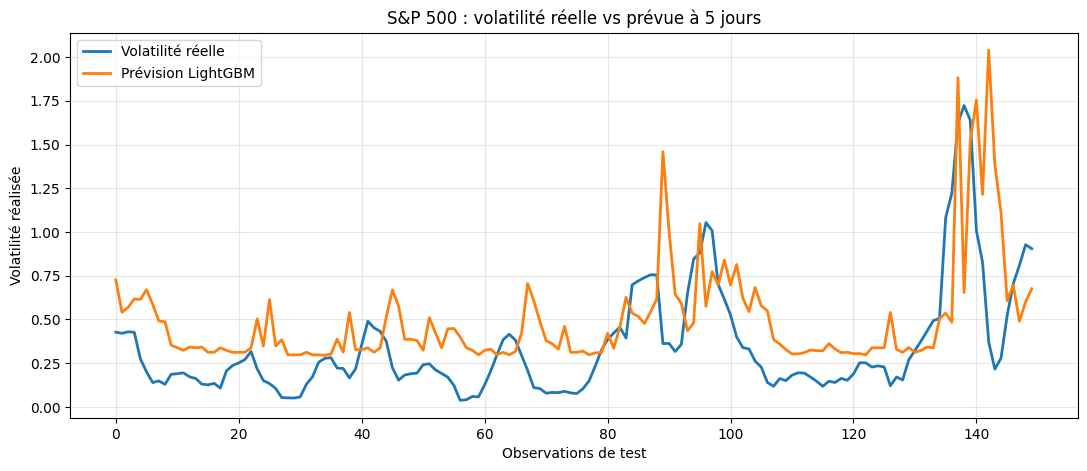

In [ ]:

import matplotlib.pyplot as plt

# Comparaison sur les 150 premières observations du test
n = 150

plt.figure(figsize=(13, 5))

plt.plot(
    y_test.iloc[:n].to_numpy(),
    label="Volatilité réelle",
    linewidth=2
)

plt.plot(
    predictions[:n],
    label="Prévision LightGBM",
    linewidth=2
)

plt.title("S&P 500 : volatilité réelle vs prévue à 5 jours")
plt.xlabel("Observations de test")
plt.ylabel("Volatilité réalisée")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


,Variable,Importance
1,rv_w,319
5,vix,302
2,rv_m,250
3,ret,215
0,rv_d,197
4,ret_neg,117


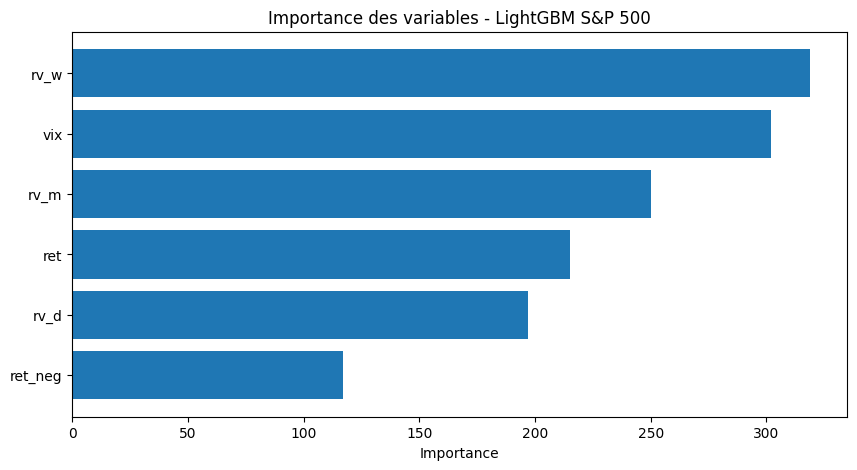

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": modele.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 5))
plt.barh(
    importance["Variable"],
    importance["Importance"]
)
plt.gca().invert_yaxis()
plt.title("Importance des variables - LightGBM S&P 500")
plt.xlabel("Importance")
plt.show()


In [ ]:

# Préparer les données TSX
df_tsx = features_tsx.copy()

variables = [
    "rv_d", "rv_w", "rv_m",
    "ret", "ret_neg", "vix"
]

X_tsx = df_tsx[variables]
y_tsx = df_tsx["y_h5"]

# Séparation chronologique 80 % / 20 %
n_tsx = int(len(df_tsx) * 0.8)

X_train_tsx = X_tsx.iloc[:n_tsx]
X_test_tsx = X_tsx.iloc[n_tsx:]

y_train_tsx = y_tsx.iloc[:n_tsx]
y_test_tsx = y_tsx.iloc[n_tsx:]

# Entraîner LightGBM
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

modele_tsx = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

modele_tsx.fit(X_train_tsx, y_train_tsx)

# Prévisions
predictions_tsx = modele_tsx.predict(X_test_tsx)

# Évaluation
mae_tsx = mean_absolute_error(
    y_test_tsx, predictions_tsx
)

rmse_tsx = np.sqrt(
    mean_squared_error(y_test_tsx, predictions_tsx)
)

print("LightGBM TSX entraîné avec succès !")
print("MAE TSX :", round(mae_tsx, 4))
print("RMSE TSX :", round(rmse_tsx, 4))


LightGBM TSX entraîné avec succès !
MAE TSX : 0.2306
RMSE TSX : 0.632


In [ ]:

# Prévision naïve TSX
prediction_naive_tsx = X_test_tsx["rv_w"]

# Erreurs de la référence
mae_naive_tsx = mean_absolute_error(
    y_test_tsx, prediction_naive_tsx
)

rmse_naive_tsx = np.sqrt(
    mean_squared_error(y_test_tsx, prediction_naive_tsx)
)

# Gain de LightGBM par rapport à la référence
gain_tsx = (
    (rmse_naive_tsx - rmse_tsx)
    / rmse_naive_tsx * 100
)

print("COMPARAISON TSX")
print("MAE LightGBM :", round(mae_tsx, 4))
print("MAE référence :", round(mae_naive_tsx, 4))
print("RMSE LightGBM :", round(rmse_tsx, 4))
print("RMSE référence :", round(rmse_naive_tsx, 4))
print("Gain RMSE :", round(gain_tsx, 2), "%")


COMPARAISON TSX
MAE LightGBM : 0.2306
MAE référence : 0.2355
RMSE LightGBM : 0.632
RMSE référence : 0.6413
Gain RMSE : 1.44 %


,Variable,Importance
1,rv_w,620
0,rv_d,545
5,vix,484
2,rv_m,458
3,ret,370
4,ret_neg,323


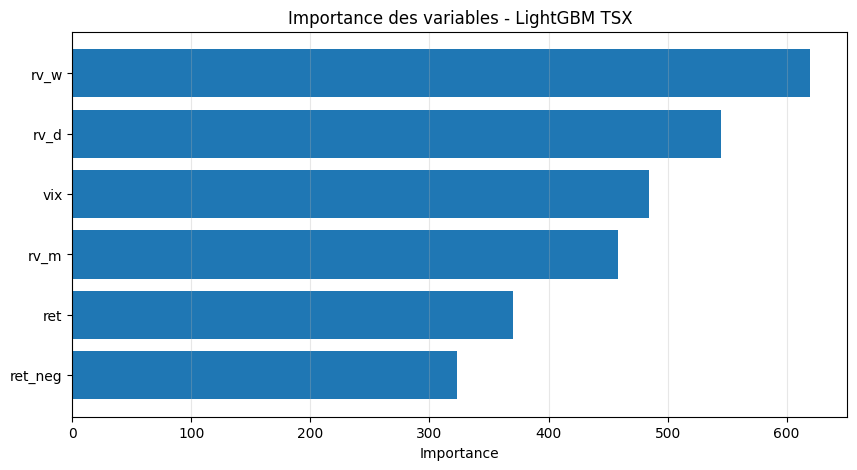

In [ ]:

# Importance des variables du TSX
importance_tsx = pd.DataFrame({
    "Variable": X_train_tsx.columns,
    "Importance": modele_tsx.feature_importances_
})

importance_tsx = importance_tsx.sort_values(
    by="Importance",
    ascending=False
)

display(importance_tsx)

# Graphique
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.barh(
    importance_tsx["Variable"],
    importance_tsx["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Importance des variables - LightGBM TSX")
plt.xlabel("Importance")
plt.grid(axis="x", alpha=0.3)
plt.show()


,Marché,MAE LightGBM,RMSE LightGBM,MAE référence,RMSE référence,Gain RMSE (%)
0,S&P 500,0.3325,0.8687,0.3946,1.1253,22.8055
1,TSX,0.2306,0.6320,0.2355,0.6413,1.4431


Tableau comparatif enregistré !


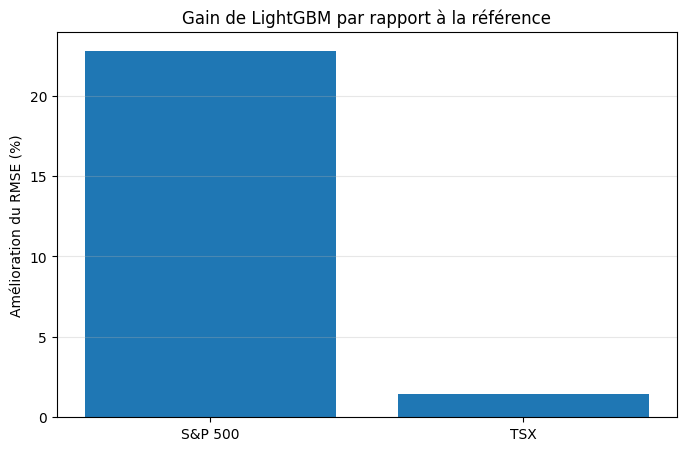

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

comparaison_finale = pd.DataFrame({
    "Marché": ["S&P 500", "TSX"],
    "MAE LightGBM": [mae, mae_tsx],
    "RMSE LightGBM": [rmse, rmse_tsx],
    "MAE référence": [mae_naif, mae_naive_tsx],
    "RMSE référence": [rmse_naif, rmse_naive_tsx],
    "Gain RMSE (%)": [gain, gain_tsx]
})

display(comparaison_finale.round(4))

comparaison_finale.to_csv(
    "/content/comparaison_spx_tsx.csv",
    index=False
)

print("Tableau comparatif enregistré !")

plt.figure(figsize=(8, 5))
plt.bar(
    comparaison_finale["Marché"],
    comparaison_finale["Gain RMSE (%)"]
)
plt.ylabel("Amélioration du RMSE (%)")
plt.title("Gain de LightGBM par rapport à la référence")
plt.grid(axis="y", alpha=0.3)
plt.show()
